In [ ]:
from google.colab import files

# This will prompt you to select one or more files from your computer
uploaded = files.upload()

Saving MWI_2010_household.dta to MWI_2010_household.dta


In [ ]:
import os
DATAPATH = os.path.join(os.getcwd())

In [ ]:
import pandas as pd

mwi_hhold = pd.read_stata(os.path.join(DATAPATH, 'MWI_2010_household.dta'))

In [ ]:
mwi_hhold.shape

(12271, 347)

In [ ]:
mwi_hhold.head()

,hid,wta_hh,wta_pop,der_hhsize,poor,hld_dwelloccu,hld_dwelltype,hld_walls,hld_roof,hld_floor,...,com_weeklymrkt,com_postoffice,com_publicphone,com_distprimary,com_classrooms,com_schoolelec,com_medicines,com_clinic,com_distclinic,com_bank
0,101010160009,126.560097,759.360596,6,Poor,Owned,Traditional,Compacted earth,Grass,Smoothed mud,...,Yes,No,NO,NaN,Yes,No,No,No,21 to 25 kilometers,No
1,101010160033,126.560097,506.240387,4,Poor,Owned,Traditional,Compacted earth,Grass,Smoothed mud,...,Yes,No,NO,NaN,Yes,No,No,No,21 to 25 kilometers,No
2,101010160060,126.560097,1265.600952,10,Poor,Owned,Semi-Permanent,Burnt bricks,Grass,Smoothed mud,...,Yes,No,NO,NaN,Yes,No,No,No,21 to 25 kilometers,No
3,101010160068,126.560097,1139.040894,9,Poor,Owned,Traditional,Mud,Grass,Smoothed mud,...,Yes,No,NO,NaN,Yes,No,No,No,21 to 25 kilometers,No
4,101010160069,126.560097,126.560097,1,Non-poor,Owned,Traditional,Mud brick,Grass,Smoothed mud,...,Yes,No,NO,NaN,Yes,No,No,No,21 to 25 kilometers,No


In [ ]:
mwi_hhold.dtypes

,0
hid,object
wta_hh,float32
wta_pop,float32
der_hhsize,int8
poor,category
...,...
com_schoolelec,category
com_medicines,category
com_clinic,category
com_distclinic,category


In [ ]:

mwi_hhold.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12271 entries, 0 to 12270
Columns: 347 entries, hid to com_bank
dtypes: category(340), float32(2), float64(2), int8(2), object(1)
memory usage: 4.4+ MB


In [ ]:
object_columns = mwi_hhold.select_dtypes(include=['object']).columns
object_columns

Index(['hid'], dtype='object')

In [ ]:
mwi_hhold = mwi_hhold.set_index('hid')

In [ ]:
mwi_hhold.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12271 entries, 101010160009 to 315556140434
Columns: 346 entries, wta_hh to com_bank
dtypes: category(340), float32(2), float64(2), int8(2)
memory usage: 4.4+ MB


In [ ]:
mwi_hhold.describe()

,wta_hh,wta_pop,der_hhsize,hld_rooms,hld_nbcellpho,hld_selfscale
count,12271.000000,12271.000000,12271.000000,12271.000000,12270.000000,12270.000000
mean,250.389130,1149.003174,4.596936,2.609812,0.604482,2.018093
std,173.354446,1035.947998,2.220238,1.192197,1.000023,0.903800
min,6.620400,11.241800,1.000000,0.000000,0.000000,1.000000
25%,128.255005,442.015991,3.000000,2.000000,0.000000,1.000000
50%,210.696106,857.700623,4.000000,2.000000,0.000000,2.000000
75%,336.460785,1553.185181,6.000000,3.000000,1.000000,3.000000
max,1938.614258,17447.527344,19.000000,15.000000,16.000000,6.000000


In [ ]:
mwi_hhold['poor'] = (mwi_hhold['poor']=='Poor').astype(int)

In [ ]:
# 1. Convert target variable to binary (True/False or 1/0)
# Adjust the condition depending on how your raw labels are spelled
print(mwi_hhold['poor'].value_counts())

poor
0    6733
1    5538
Name: count, dtype: int64


In [ ]:
# 2. Drop rows with too many missing values (minor missing rows)
nan_counts = (mwi_hhold.applymap(pd.isnull)
              .sum(axis=0)
              .sort_values(ascending=False))
nan_cols = nan_counts[(nan_counts > 0) & (nan_counts < 10)].index.values
mwi_hhold = mwi_hhold.dropna(subset=nan_cols)

/tmp/ipykernel_3216/1089738027.py:2: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  nan_counts = (mwi_hhold.applymap(pd.isnull)


In [ ]:
mwi_hhold.shape

(12246, 346)

In [ ]:
mwi_hhold_encoded = pd.get_dummies(mwi_hhold, drop_first=True)

In [ ]:
# 3. For remaining missing values in features, you can fill them or drop them
# Example: Fill missing numerical values with median, or categoricals with a placeholder
for col in mwi_hhold_encoded.columns:
  mwi_hhold_encoded[col] = mwi_hhold_encoded[col].fillna(mwi_hhold_encoded[col].median())

In [ ]:
mwi_hhold_encoded.shape

(12246, 477)

In [ ]:
mwi_hhold_encoded.isna().sum().sum()

np.int64(0)

In [ ]:
# Drop columns with only 1 unique value (constant columns)
mwi_hhold_encoded = mwi_hhold_encoded.loc[:, mwi_hhold_encoded.nunique() > 1]

# Drop duplicate columns if any were created
mwi_hhold_encoded=mwi_hhold_encoded.T.drop_duplicates().T

print(f"Final clean shape: {mwi_hhold_encoded.shape}")

Final clean shape: (12246, 474)


In [ ]:
mwi_subsample = mwi_hhold_encoded.groupby('poor').apply(pd.DataFrame.sample, frac=0.1).reset_index(level='poor', drop=True)

/tmp/ipykernel_3216/3678652524.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  mwi_subsample = mwi_hhold_encoded.groupby('poor').apply(pd.DataFrame.sample, frac=0.1).reset_index(level='poor', drop=True)


In [ ]:
mwi_subsample.shape

(1225, 474)

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
mwi_train, mwi_test = train_test_split(mwi_subsample,
                                       test_size=0.25,
                                       random_state=1443,
                                       stratify=mwi_subsample.poor)

In [ ]:
import os
import sys
import json

import numpy as np
import pandas as pd

from matplotlib import pyplot as plt
from IPython.display import display
import seaborn as sns
sns.set()

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def get_vif(X, intercept_col='intercept'):
    if intercept_col is not None and intercept_col in X.columns:
        X = X.copy().drop(intercept_col, axis=1)

    vi_factors = [variance_inflation_factor(X.values, i)
                             for i in range(X.shape[1])]

    return pd.Series(vi_factors,
                     index=X.columns,
                     name='variance_inflaction_factor')

In [ ]:
# Convert targets explicitly to int
y_train = mwi_train['poor'].astype(int).values
y_test = mwi_test['poor'].astype(int).values

# Ensure features are float numbers rather than object dtype
X_train = mwi_train.drop(columns=['poor']).astype(float)
X_test = mwi_test.drop(columns=['poor']).astype(float)

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)

X_test = scaler.transform(X_test)


In [ ]:
from sklearn import svm
clf = svm.SVC(kernel = 'linear', probability= True)
clf.fit(X_train, y_train)

SVC(kernel='linear', probability=True)

In [ ]:
y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)[:,1]

In [ ]:
import sklearn.metrics as mtc
acc = mtc.accuracy_score(y_test, y_pred)
f1  = mtc.f1_score(y_test , y_pred)
recall  = mtc.recall_score(y_test , y_pred)
precision = mtc.precision_score(y_test , y_pred)
cohen_kappa  = mtc.cohen_kappa_score(y_test , y_pred)
auc_roc = mtc.roc_auc_score(y_test , y_prob)


In [ ]:
from sklearn.metrics import log_loss
cross_entropy  = log_loss(y_test , y_prob)

In [ ]:
import pandas as pd

# 1. From a dictionary of lists (most common)
data = {
    'Metric': ['Accuracy', 'F1', 'Recall', 'Precision', 'AUC_ROC'],
    'Score': [acc, f1, recall, precision, auc_roc]
}

metrics_df = pd.DataFrame(data)
metrics_df

,Metric,Score
0,Accuracy,0.804560
1,F1,0.787234
2,Recall,0.798561
3,Precision,0.776224
4,AUC_ROC,0.880546


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn import metrics

fpr, tpr, thresholds = metrics.roc_curve(y_test, y_prob)
roc_auc = metrics.auc(fpr, tpr)
display = metrics.RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc)

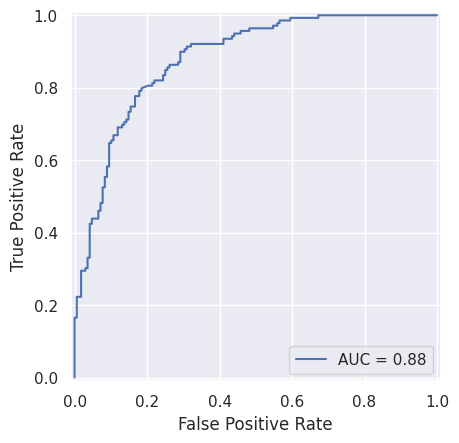

In [ ]:
display.plot()


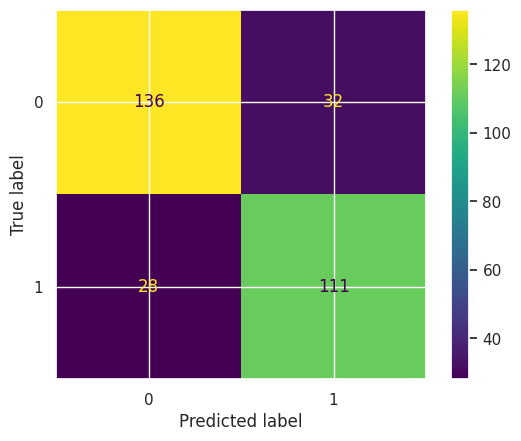

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm)
disp.plot()